# Analyse: EDA und statistische Tests

**ZHAW Data Analytics HS2026 · Gruppenprojekt «Strompreise der Gemeinden» · Teil Subraj**

Dieses Notebook deckt Pflicht 4 (EDA, grafisch und nicht-grafisch) und Bonus 4 (ANOVA und Korrelation mit p-Wert) ab. Regression, Modellgüte und k-means folgen in einem zweiten Teil.

**Forschungsfrage:** Welche Merkmale einer Gemeinde erklären die Höhe ihres Strompreises für Haushalte, und haben sich diese Zusammenhänge mit dem Preisanstieg 2023 verändert?

**Datenbasis:** Kategorie H4 (4500 kWh pro Jahr), Produkt `standard`, die 2087 Gemeinden, die in allen drei Jahren einen Preis haben. Für den Zeitvergleich wird nur `total` verwendet, weil nur diese Spalte in allen drei Jahren dieselben Bestandteile enthält (siehe Projektanleitung, Abschnitt 4).

| Abschnitt | Inhalt | Unterfrage |
|---|---|---|
| 0 | Daten aus SQLite laden | |
| 1 | Überblick und Datenqualität | |
| 2 | Verteilung der Preise pro Jahr | 1 |
| 3 | Veränderung zwischen den Jahren | 4 |
| 4 | Preisbestandteile | 1 |
| 5 | Gemeindemerkmale | 2 |
| 6 | Sprachregionen und Kantone | 1 |
| 7 | Netzbetreiber | Vorbehalt 5b |
| 8 | Tests: t-Test, ANOVA, Korrelation | 1, 2, 4 |
| 9 | Zwischenfazit | |

## 0 · Daten laden

Die Analysetabelle kommt aus Metehans SQLite-Datenbank (`v_analyse`, eine Zeile pro Gemeinde) und die Preisbestandteile aus `v_preis_h4`. Beide Abfragen laufen per SQL aus Python.

Kanton, Sprachregion und Gemeindetyp stehen noch nicht in der Datenbank, sondern nur in Lennys verbundener Tabelle. Sie werden über `gemeinde_nr` dazugeholt, ebenso die Netzbetreiber-Zuordnung (bei mehreren Betreibern der mit der kleinsten `netzbetreiber_id`).

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


def finde_wurzel(start: Path) -> Path:
    # Klettert nach oben, bis daten/ und scripts/ nebeneinander liegen
    for ordner in [start, *start.parents]:
        if (ordner / "daten").is_dir() and (ordner / "scripts").is_dir():
            return ordner
    raise RuntimeError(f"Repo-Wurzel von {start} aus nicht gefunden")


WURZEL = finde_wurzel(Path.cwd().resolve())
DB = WURZEL / "sql" / "strompreise.db"
VERBUNDEN = WURZEL / "daten" / "verbunden" / "strompreise_gemeinden.csv"
JAHRE = [2021, 2024, 2027]

# Farben: feste Reihenfolge, geprüft auf Farbfehlsichtigkeit
FARBE = {2021: "#2a78d6", 2024: "#eb6834", 2027: "#1baf7a"}
REGION_FARBE = {"Deutsch": "#2a78d6", "Französisch": "#eb6834",
                "Italienisch": "#1baf7a", "Rätoromanisch": "#eda100"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#898781",
    "ytick.color": "#898781", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
con = sqlite3.connect(DB)

df = pd.read_sql("SELECT * FROM v_analyse", con)
bestandteile = pd.read_sql('''
    SELECT p.*
    FROM v_preis_h4 p
    JOIN v_analyse a ON a.gemeinde_nr = p.gemeinde_nr      -- nur die 2087 Gemeinden der Analyse
''', con)

zusatz = pd.read_csv(VERBUNDEN, usecols=["gemeinde_nr", "netzbetreiber_id", "netzbetreiber",
                                         "kanton", "kanton_nr", "sprachregion", "gemeindetyp_9",
                                         "anz_gemeinden_betreiber"])
vorher = len(df)
df = df.merge(zusatz, on="gemeinde_nr", how="left", validate="one_to_one")
assert len(df) == vorher == 2087, "Zeilenzahl hat sich beim Verbinden verändert"
assert df["kanton"].notna().all(), "Gemeinde ohne Kanton"

# Veränderungen in Rappen pro kWh
df["anstieg_21_24"] = df["total_2024"] - df["total_2021"]
df["anstieg_24_27"] = df["total_2027"] - df["total_2024"]
df["anstieg_21_27"] = df["total_2027"] - df["total_2021"]

print(f"{len(df)} Gemeinden, {df['netzbetreiber_id'].nunique()} Netzbetreiber, "
      f"{df['kanton'].nunique()} Kantone")
print(f"Bestandteile: {len(bestandteile)} Zeilen ({bestandteile['jahr'].value_counts().sort_index().to_dict()})")

2087 Gemeinden, 485 Netzbetreiber, 26 Kantone
Bestandteile: 6261 Zeilen ({2021: 2087, 2024: 2087, 2027: 2087})

## 1 · Überblick und Datenqualität

In [3]:
df.head()

,gemeinde_nr,gemeinde,anzahl_netzbetreiber,total_2021,total_2024,total_2027,einwohner,dichte,flaeche_total,beschaeftigte,anteil_65plus,netzbetreiber_id,netzbetreiber,kanton,kanton_nr,sprachregion,gemeindetyp_9,anz_gemeinden_betreiber,anstieg_21_24,anstieg_24_27,anstieg_21_27
0,1,Aeugst am Albis,1,17.122,31.609,23.872,1981.0,250.442478,7.91,442.0,18.021201,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,23.0,133,14.487,-7.737,6.75
1,2,Affoltern am Albis,1,17.122,31.609,23.872,12303.0,1161.756374,10.59,6920.0,18.166301,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,11.0,133,14.487,-7.737,6.75
2,3,Bonstetten,1,17.122,31.609,23.872,5572.0,749.932705,7.43,1014.0,16.529074,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,22.0,133,14.487,-7.737,6.75
3,4,Hausen am Albis,1,17.122,31.609,23.872,3751.0,275.808824,13.60,1021.0,17.995201,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,22.0,133,14.487,-7.737,6.75
4,5,Hedingen,1,17.122,31.609,23.872,3778.0,578.560490,6.53,1478.0,16.728428,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,11.0,133,14.487,-7.737,6.75


In [4]:
uebersicht = pd.DataFrame({
    "Datentyp": df.dtypes.astype(str),
    "fehlend": df.isna().sum(),
    "fehlend_%": (df.isna().mean() * 100).round(1),
    "verschiedene_Werte": df.nunique(),
})
uebersicht

,Datentyp,fehlend,fehlend_%,verschiedene_Werte
gemeinde_nr,int64,0,0.0,2087
gemeinde,str,0,0.0,2087
anzahl_netzbetreiber,int64,0,0.0,4
total_2021,float64,0,0.0,663
total_2024,float64,0,0.0,663
total_2027,float64,0,0.0,672
einwohner,float64,0,0.0,1726
dichte,float64,0,0.0,2082
flaeche_total,float64,0,0.0,1447
beschaeftigte,float64,88,4.2,1338


Fehlende Werte gibt es nur an zwei Stellen. Bei `beschaeftigte` fehlen 88 Werte, weil das BFS sie aus Datenschutzgründen unterdrückt (Status Q). Diese Gemeinden sind deutlich kleiner als der Rest (siehe Integrationsdokumentation, Abschnitt 7). Bei `gemeindetyp_9` fehlt ein Wert (Prez, Fusion mit uneinheitlichen Vorgängern). Für das Modell heisst das: Variante ohne Beschäftigte auf allen 2087 Gemeinden, Variante mit Beschäftigten auf 1999 Gemeinden, und beide vergleichen.

In [5]:
# Plausibilität: keine negativen oder Nullwerte bei Grössen, die später logarithmiert werden
for spalte in ["einwohner", "dichte", "flaeche_total", "beschaeftigte"]:
    print(f"{spalte:<15} kleinster Wert: {df[spalte].min():>10.2f}   Werte <= 0: {(df[spalte] <= 0).sum()}")
print("\nGemeinden mit mehreren Netzbetreibern:", (df["anzahl_netzbetreiber"] > 1).sum())
print("Doppelte gemeinde_nr:", df["gemeinde_nr"].duplicated().sum())

einwohner       kleinster Wert:      32.00   Werte <= 0: 0
dichte          kleinster Wert:       0.86   Werte <= 0: 0
flaeche_total   kleinster Wert:       0.31   Werte <= 0: 0
beschaeftigte   kleinster Wert:      11.00   Werte <= 0: 0

Gemeinden mit mehreren Netzbetreibern: 150
Doppelte gemeinde_nr: 0

## 2 · Verteilung der Preise pro Jahr

### 2.1 Kennzahlen
Neben Mittelwert und Median werden Streuungsmasse berechnet. Der Variationskoeffizient (Standardabweichung geteilt durch Mittelwert) macht die Streuung zwischen Jahren mit unterschiedlichem Preisniveau vergleichbar.

In [6]:
def kennzahlen(x: pd.Series) -> pd.Series:
    q1, q3 = x.quantile([0.25, 0.75])
    return pd.Series({
        "n": x.count(), "Mittelwert": x.mean(), "Median": x.median(), "Std": x.std(),
        "Min": x.min(), "Q1": q1, "Q3": q3, "Max": x.max(), "IQR": q3 - q1,
        "Spannweite": x.max() - x.min(), "Var.koeff.": x.std() / x.mean(),
        "Schiefe": x.skew(), "Kurtosis": x.kurt(),
        "Ausreisser (1.5 IQR)": ((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum(),
    })

preis_kennzahlen = pd.DataFrame({j: kennzahlen(df[f"total_{j}"]) for j in JAHRE}).round(2)
preis_kennzahlen

,2021,2024,2027
n,2087.00,2087.00,2087.00
Mittelwert,20.86,31.99,27.25
Median,20.53,32.15,26.91
Std,2.99,3.71,3.05
Min,7.96,10.22,10.56
Q1,19.09,30.27,25.59
Q3,22.51,33.36,28.79
Max,27.65,50.62,45.88
IQR,3.42,3.09,3.20
Spannweite,19.69,40.39,35.32


### 2.2 Histogramme

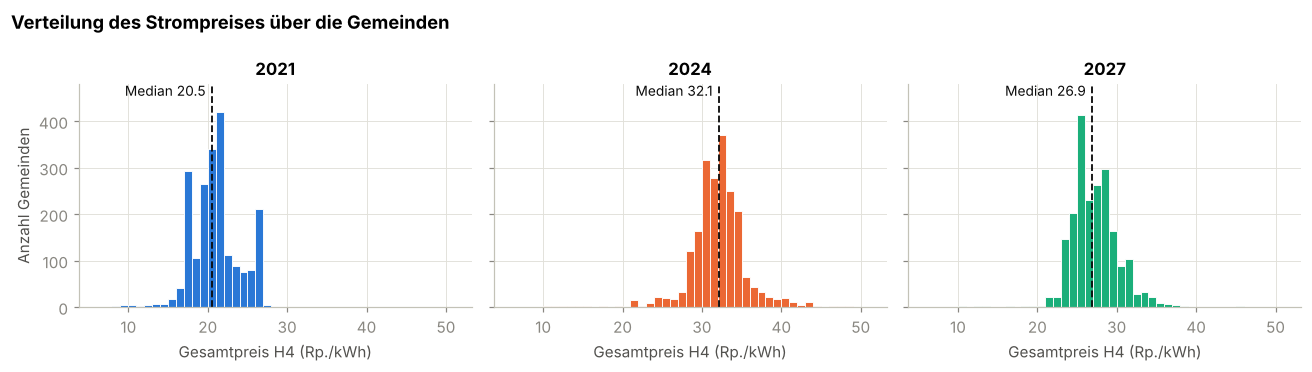

In [7]:
fig, achsen = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True, sharey=True)
bins = np.arange(6, 52, 1)
for ax, j in zip(achsen, JAHRE):
    x = df[f"total_{j}"]
    ax.hist(x, bins=bins, color=FARBE[j], edgecolor="white", linewidth=0.6)
    ax.axvline(x.median(), color="#0b0b0b", linewidth=1.2, linestyle="--")
    ax.text(x.median() - 0.8, 455, f"Median {x.median():.1f}", fontsize=9,
            color="#0b0b0b", ha="right")
    ax.set_title(str(j))
    ax.set_xlabel("Gesamtpreis H4 (Rp./kWh)")
achsen[0].set_ylabel("Anzahl Gemeinden")
achsen[0].set_ylim(0, 480)
fig.suptitle("Verteilung des Strompreises über die Gemeinden", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

### 2.3 Boxplots

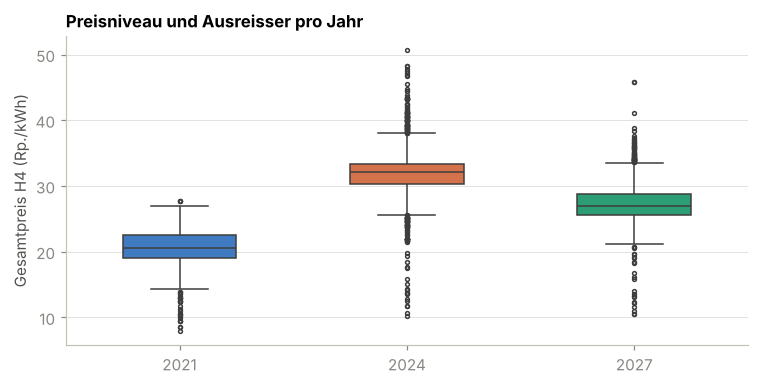

In [8]:
lang = df.melt(id_vars="gemeinde_nr", value_vars=[f"total_{j}" for j in JAHRE],
               var_name="jahr", value_name="preis")
lang["jahr"] = lang["jahr"].str[-4:].astype(int)

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.boxplot(data=lang, x="jahr", y="preis", hue="jahr", palette=FARBE, legend=False,
            width=0.5, fliersize=2.5, linewidth=1, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Gesamtpreis H4 (Rp./kWh)")
ax.set_title("Preisniveau und Ausreisser pro Jahr", loc="left")
fig.tight_layout()

#### Interpretation

2021 lagen die Preise eng um einen Median von 20.5 Rp./kWh, die Verteilung ist nicht schief. 2024 stieg der Mittelwert auf 32.0 Rp., das sind 53 Prozent mehr. Gleichzeitig verdoppelte sich die Spannweite von 19.7 auf 40.4 Rp., und die Zahl der Ausreisser nach der 1.5-IQR-Regel stieg von 30 auf 184. Die Kurtosis von 6.0 zeigt dasselbe: Die Masse der Gemeinden liegt eng beieinander, an beiden Rändern gibt es aber deutlich mehr Extremwerte.

Relativ zum Preisniveau hat die Streuung dagegen abgenommen. Der Variationskoeffizient sinkt von 0.14 (2021) auf 0.12 (2024) und 0.11 (2027). In Rappen sind die Unterschiede zwischen Gemeinden grösser geworden, im Verhältnis zum Preis nicht.

2027 liegt der Median bei 26.9 Rp., also 6.4 Rp. über 2021. Die Preise sind gesunken, aber nicht auf das Vorkrisenniveau.

Das Histogramm 2021 hat auffällige Spitzen, etwa bei 17 Rp. Das sind keine Messfehler: Ein grosser Netzbetreiber versorgt Hunderte Gemeinden zum selben Preis, die EKZ zum Beispiel alle ihre Gemeinden zu 17.1 Rp. Abschnitt 7 geht darauf ein.

## 3 · Veränderung zwischen den Jahren

Wichtig für den zweiten Teil der Forschungsfrage: Bleiben die günstigen Gemeinden günstig, oder mischt die Krise die Rangfolge neu? Gemessen wird das mit der Rangkorrelation nach Spearman zwischen den Jahren.

In [9]:
df[["anstieg_21_24", "anstieg_24_27", "anstieg_21_27"]].describe().round(2)

,anstieg_21_24,anstieg_24_27,anstieg_21_27
count,2087.00,2087.00,2087.00
mean,11.13,-4.74,6.39
std,4.39,3.10,3.86
min,1.20,-20.24,-2.15
25%,9.03,-5.93,4.77
50%,11.44,-4.68,6.75
75%,14.14,-3.89,8.41
max,31.37,11.32,27.65


In [10]:
print(f"Gemeinden, die 2027 günstiger sind als 2021: {(df['anstieg_21_27'] < 0).sum()} "
      f"({(df['anstieg_21_27'] < 0).mean():.1%})")
print(f"Gemeinden, die 2027 teurer sind als 2024:    {(df['anstieg_24_27'] > 0).sum()} "
      f"({(df['anstieg_24_27'] > 0).mean():.1%})\n")

paare = [(2021, 2024), (2024, 2027), (2021, 2027)]
zeilen = []
for a, b in paare:
    sp = stats.spearmanr(df[f"total_{a}"], df[f"total_{b}"])
    pe = stats.pearsonr(df[f"total_{a}"], df[f"total_{b}"])
    zeilen.append({"Jahre": f"{a} – {b}",
                   "Spearman rho": round(sp.statistic, 3), "p (Spearman)": f"{sp.pvalue:.2g}",
                   "Pearson r": round(pe.statistic, 3), "p (Pearson)": f"{pe.pvalue:.2g}"})
rang = pd.DataFrame(zeilen)
rang

Gemeinden, die 2027 günstiger sind als 2021: 227 (10.9%)
Gemeinden, die 2027 teurer sind als 2024:    165 (7.9%)

,Jahre,Spearman rho,p (Spearman),Pearson r,p (Pearson)
0,2021 – 2024,0.082,0.00017,0.155,1.1e-12
1,2024 – 2027,0.567,5.6e-178,0.594,3e-199
2,2021 – 2027,0.168,1e-14,0.184,2.4e-17


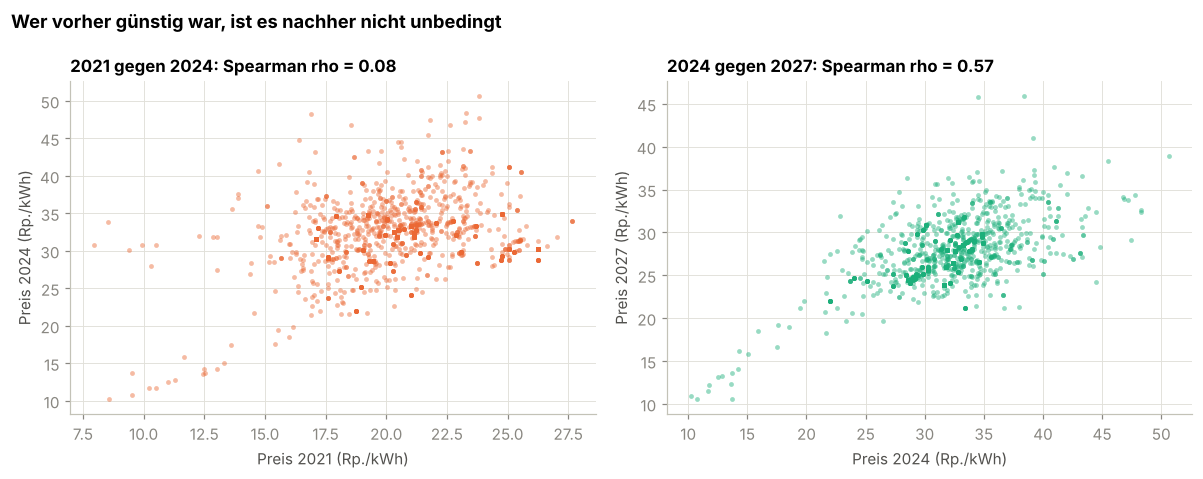

In [11]:
fig, achsen = plt.subplots(1, 2, figsize=(11, 4.4), sharex=False)
for ax, (a, b) in zip(achsen, [(2021, 2024), (2024, 2027)]):
    ax.scatter(df[f"total_{a}"], df[f"total_{b}"], s=10, alpha=0.45, color=FARBE[b], linewidths=0)
    rho = stats.spearmanr(df[f"total_{a}"], df[f"total_{b}"]).statistic
    ax.set_xlabel(f"Preis {a} (Rp./kWh)")
    ax.set_ylabel(f"Preis {b} (Rp./kWh)")
    ax.set_title(f"{a} gegen {b}: Spearman rho = {rho:.2f}", loc="left")
fig.suptitle("Wer vorher günstig war, ist es nachher nicht unbedingt", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

#### Interpretation

Die Rangkorrelation zwischen 2021 und 2024 beträgt nur 0.08. Wo eine Gemeinde vor der Krise in der Rangfolge stand, sagt fast nichts darüber, wo sie auf dem Höhepunkt stand. Die Krise hat die Rangfolge neu gemischt. Zwischen 2024 und 2027 liegt die Rangkorrelation bei 0.57: Wer 2024 teuer war, ist es 2027 eher noch.

Im linken Streudiagramm fällt eine kleine Gruppe unten links auf, die in beiden Jahren unter 15 Rp. liegt. Eine naheliegende Vermutung sind Betreiber mit eigener Produktion, die vom Marktpreis kaum betroffen waren. Geprüft ist das nicht, die Daten enthalten keine Angabe zur Produktion.

227 Gemeinden (10.9 Prozent) zahlen 2027 weniger als 2021, 165 Gemeinden (7.9 Prozent) zahlen 2027 sogar mehr als 2024.

Für die Forschungsfrage heisst das: Wenn sich die Rangfolge so stark verschiebt, können die Gemeindemerkmale, die den Preis 2021 erklären, nicht dieselben sein wie 2024. Das Modell pro Jahr wird unterschiedliche Koeffizienten zeigen.

## 4 · Preisbestandteile

Für Mittelwerte über die Jahre wird die Netznutzung **inklusive** Messtarif verwendet (`netznutzung_inkl_mess` aus Metehans View), weil der Messtarif bis 2025 in der Netznutzung steckte.

### 4.1 Mittlere Zusammensetzung des Preises

In [12]:
TEILE = ["energie", "netznutzung_inkl_mess", "abgaben", "netzzuschlag"]
NAMEN = {"energie": "Energie", "netznutzung_inkl_mess": "Netznutzung inkl. Messung",
         "abgaben": "Abgaben", "netzzuschlag": "Netzzuschlag"}
mittel = bestandteile.groupby("jahr")[TEILE + ["total"]].mean().round(2)
mittel

,energie,netznutzung_inkl_mess,abgaben,netzzuschlag,total
jahr,,,,,
2021,7.94,9.78,0.85,2.29,20.86
2024,15.58,13.23,0.88,2.30,31.99
2027,11.19,12.87,0.90,2.30,27.25


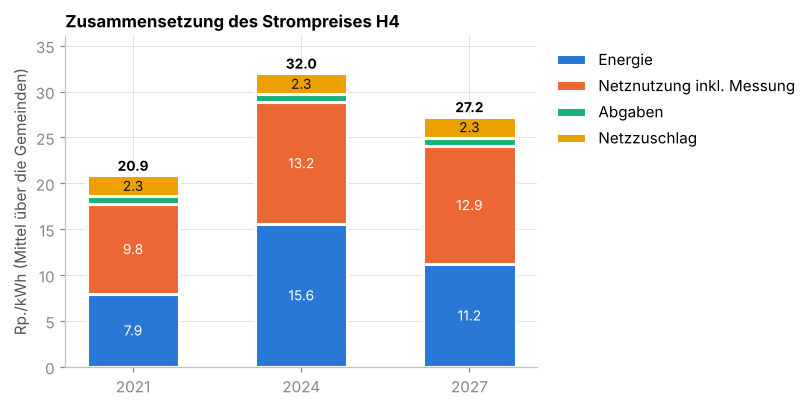

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
farben_teile = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
unten = np.zeros(len(JAHRE))
for teil, farbe in zip(TEILE, farben_teile):
    werte = mittel.loc[JAHRE, teil].values
    ax.bar([str(j) for j in JAHRE], werte, bottom=unten, color=farbe, width=0.55,
           edgecolor="white", linewidth=2, label=NAMEN[teil])
    for i, (w, u) in enumerate(zip(werte, unten)):
        if w > 1.5:
            ax.text(i, u + w / 2, f"{w:.1f}", ha="center", va="center", fontsize=9,
                    color="#0b0b0b" if farbe == "#eda100" else "white")
    unten += werte
for i, t in enumerate(mittel.loc[JAHRE, "total"]):
    ax.text(i, t + 0.5, f"{t:.1f}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylabel("Rp./kWh (Mittel über die Gemeinden)")
ax.set_title("Zusammensetzung des Strompreises H4", loc="left")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_ylim(0, 36)
fig.tight_layout()

### 4.2 Welcher Bestandteil erklärt die Unterschiede zwischen Gemeinden?

Der Mittelwert sagt, woraus der Preis besteht. Die Frage hier ist eine andere: Welcher Bestandteil sorgt dafür, dass eine Gemeinde teurer ist als eine andere? Dafür wird die Varianz des Gesamtpreises zerlegt. Weil `total` die Summe der Bestandteile ist, gilt

$\mathrm{Var}(\text{total}) = \sum_k \mathrm{Cov}(\text{Bestandteil}_k, \text{total})$,

und der Anteil eines Bestandteils ist $\mathrm{Cov}(\text{Bestandteil}_k, \text{total}) / \mathrm{Var}(\text{total})$. Die Anteile ergeben zusammen 100 Prozent, einzelne können negativ sein.

In [14]:
def varianzanteile(gruppe: pd.DataFrame) -> pd.Series:
    var_total = gruppe["total"].var()
    return pd.Series({NAMEN[t]: gruppe[t].cov(gruppe["total"]) / var_total * 100 for t in TEILE})

anteile = bestandteile.groupby("jahr").apply(varianzanteile, include_groups=False).T.round(1)
anteile.loc["Summe"] = anteile.sum().round(1)
anteile

jahr,2021,2024,2027
Energie,32.0,80.3,44.8
Netznutzung inkl. Messung,55.8,21.2,54.8
Abgaben,11.4,-1.4,0.4
Netzzuschlag,0.8,-0.0,-0.0
Summe,100.0,100.1,100.0


#### Interpretation

Im Mittel hat sich der Energieanteil von 7.9 auf 15.6 Rp. fast verdoppelt, die Netznutzung stieg von 9.8 auf 13.2 Rp. Abgaben und Netzzuschlag blieben praktisch gleich.

Die Varianzzerlegung zeigt, dass sich die Ursache der Unterschiede zwischen Gemeinden umgedreht hat. 2021 erklärte die Netznutzung 56 Prozent der Streuung, also die Kosten des Netzes und damit die Geografie. 2024 erklärte die Energie 80 Prozent, also wie und wann ein Betreiber seinen Strom eingekauft hat. 2027 verteilt es sich wieder ähnlich wie 2021 (Energie 45, Netznutzung 55 Prozent).

Die Abgaben an die Gemeinden erklärten 2021 noch 11 Prozent der Unterschiede, 2024 und 2027 praktisch nichts mehr.

Die Gesamtsumme 2024 ergibt 100.1 Prozent, das ist ein Rundungseffekt.

## 5 · Gemeindemerkmale

Die Merkmale stammen nicht aus denselben Jahren wie die Preise: Einwohner, Dichte und Anteil 65+ beziehen sich auf 2019, die Beschäftigten auf 2018, die Fläche auf 2016 (Integrationsdokumentation, Abschnitt 7b). Erklärt werden also Preise von 2021 bis 2027 mit Gemeindemerkmalen von 2016 bis 2019. Für Fläche und Dichte ist das unproblematisch, weil sie sich kaum ändern. Beim Anteil 65+ und bei den Einwohnern ist der Abstand bis 2027 grösser, die Rangfolge der Gemeinden dürfte sich aber nur wenig verschoben haben. Geprüft ist das nicht.

### 5.1 Verteilungen

In [15]:
MERKMALE = ["einwohner", "dichte", "flaeche_total", "beschaeftigte", "anteil_65plus"]
MERKMAL_NAME = {"einwohner": "Einwohner", "dichte": "Dichte (Einw./km²)",
                "flaeche_total": "Fläche (km²)", "beschaeftigte": "Beschäftigte",
                "anteil_65plus": "Anteil 65+ (%)"}
merkmal_kennzahlen = pd.DataFrame({MERKMAL_NAME[m]: kennzahlen(df[m].dropna()) for m in MERKMALE}).T
merkmal_kennzahlen[["n", "Mittelwert", "Median", "Std", "Min", "Max", "Schiefe"]].round(1)

,n,Mittelwert,Median,Std,Min,Max,Schiefe
Einwohner,2087.0,4071.1,1627.0,13118.8,32.0,420217.0,19.8
Dichte (Einw./km²),2087.0,444.8,188.4,804.8,0.9,12811.0,5.9
Fläche (km²),2087.0,18.6,8.5,33.3,0.3,438.6,5.4
Beschäftigte,1999.0,2572.7,623.0,14287.6,11.0,491193.0,23.9
Anteil 65+ (%),2087.0,19.4,19.0,4.4,6.5,40.3,0.8


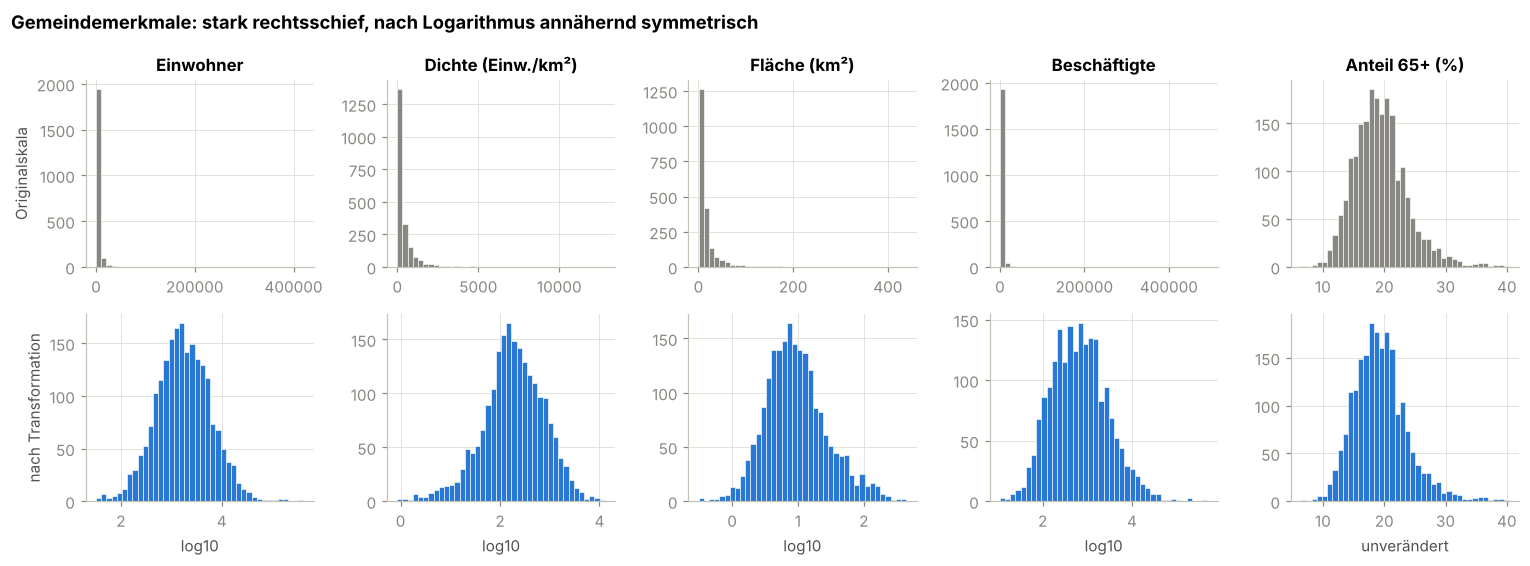

In [16]:
fig, achsen = plt.subplots(2, 5, figsize=(14, 5.2))
for i, m in enumerate(MERKMALE):
    x = df[m].dropna()
    achsen[0, i].hist(x, bins=40, color="#898781", edgecolor="white", linewidth=0.4)
    achsen[0, i].set_title(MERKMAL_NAME[m])
    if m == "anteil_65plus":
        achsen[1, i].hist(x, bins=40, color="#2a78d6", edgecolor="white", linewidth=0.4)
        achsen[1, i].set_xlabel("unverändert")
    else:
        achsen[1, i].hist(np.log10(x), bins=40, color="#2a78d6", edgecolor="white", linewidth=0.4)
        achsen[1, i].set_xlabel("log10")
achsen[0, 0].set_ylabel("Originalskala")
achsen[1, 0].set_ylabel("nach Transformation")
fig.suptitle("Gemeindemerkmale: stark rechtsschief, nach Logarithmus annähernd symmetrisch",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

Einwohner, Dichte, Fläche und Beschäftigte sind extrem rechtsschief: Der Mittelwert der Einwohner liegt bei rund 4100, der Median bei rund 1600, weil wenige Städte wie Zürich mit über 400 000 Einwohnern den Mittelwert hochziehen. Nach dem Logarithmus sind die Verteilungen annähernd symmetrisch. Für Pearson-Korrelation und Regression werden diese vier Merkmale deshalb logarithmiert. Der Anteil 65+ ist schon fast symmetrisch und bleibt unverändert.

In [17]:
# Logarithmierte Merkmale für Korrelation und Modell
for m in ["einwohner", "dichte", "flaeche_total", "beschaeftigte"]:
    df[f"log_{m}"] = np.log10(df[m])

# Zusammenhang der Merkmale untereinander (Multikollinearität vorab prüfen)
LOG_MERKMALE = ["log_einwohner", "log_dichte", "log_flaeche_total", "log_beschaeftigte", "anteil_65plus"]
df[LOG_MERKMALE].corr().round(2)

,log_einwohner,log_dichte,log_flaeche_total,log_beschaeftigte,anteil_65plus
log_einwohner,1.00,0.68,0.26,0.94,-0.14
log_dichte,0.68,1.00,-0.53,0.58,-0.30
log_flaeche_total,0.26,-0.53,1.00,0.31,0.24
log_beschaeftigte,0.94,0.58,0.31,1.00,-0.07
anteil_65plus,-0.14,-0.30,0.24,-0.07,1.00


Einwohner und Beschäftigte korrelieren sehr stark, ebenso Einwohner und Dichte. Beides zusammen in einer Regression würde die Koeffizienten instabil machen. Für das Modell muss deshalb ausgewählt werden, etwa Dichte und Fläche statt Einwohner, oder die Beschäftigten pro Einwohner als Mass für die gewerbliche Last.

### 5.2 Zusammenhang mit dem Preis

Spearman-Rangkorrelation zwischen jedem Merkmal und dem Preis beziehungsweise dem Anstieg. Spearman ist unempfindlich gegen Ausreisser und braucht keine Transformation.

Unter der Heatmap steht zu jeder Zelle der p-Wert. Weil hier viele Tests gleichzeitig laufen, gilt als Schwelle die Bonferroni-Korrektur (0.05 geteilt durch die Zahl der Tests); ein Stern markiert die Werte darunter.

p-Werte (Spearman), 25 Tests, Bonferroni-Schwelle 0.05/25 = 0.0020
Signifikant nach Bonferroni: 18 von 25

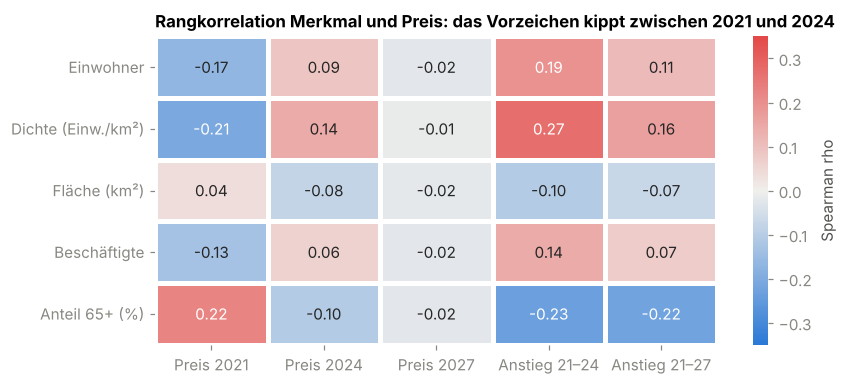

,Preis 2021,Preis 2024,Preis 2027,Anstieg 21–24,Anstieg 21–27
Einwohner,8.0e-15 *,9.8e-05 *,3.0e-01,2.6e-19 *,2.9e-07 *
Dichte (Einw./km²),1.6e-21 *,6.5e-11 *,5.6e-01,2.4e-36 *,4.2e-14 *
Fläche (km²),8.7e-02,3.0e-04 *,3.7e-01,1.9e-06 *,1.2e-03 *
Beschäftigte,3.0e-09 *,5.6e-03,3.2e-01,1.0e-10 *,1.1e-03 *
Anteil 65+ (%),3.0e-25 *,1.6e-06 *,2.7e-01,1.8e-27 *,1.2e-24 *


In [18]:
ZIELE = {"total_2021": "Preis 2021", "total_2024": "Preis 2024", "total_2027": "Preis 2027",
         "anstieg_21_24": "Anstieg 21–24", "anstieg_21_27": "Anstieg 21–27"}
rho_matrix = pd.DataFrame(index=[MERKMAL_NAME[m] for m in MERKMALE], columns=list(ZIELE.values()), dtype=float)
p_matrix = rho_matrix.copy()
for m in MERKMALE:
    for ziel, name in ZIELE.items():
        paar = df[[m, ziel]].dropna()
        ergebnis = stats.spearmanr(paar[m], paar[ziel])
        rho_matrix.loc[MERKMAL_NAME[m], name] = ergebnis.statistic
        p_matrix.loc[MERKMAL_NAME[m], name] = ergebnis.pvalue

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(rho_matrix, annot=True, fmt=".2f", cmap=sns.blend_palette(["#2a78d6", "#f0efec", "#e34948"], as_cmap=True),
            vmin=-0.35, vmax=0.35, linewidths=2, linecolor="white", cbar_kws={"label": "Spearman rho"}, ax=ax)
ax.set_title("Rangkorrelation Merkmal und Preis: das Vorzeichen kippt zwischen 2021 und 2024", loc="left")
ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout()
plt.show()

# p-Werte zu jeder Zelle der Heatmap; Bonferroni-Schwelle für alle Tests dieser Matrix
schwelle = 0.05 / p_matrix.size
print(f"p-Werte (Spearman), {p_matrix.size} Tests, Bonferroni-Schwelle 0.05/{p_matrix.size} = {schwelle:.4f}")
print(f"Signifikant nach Bonferroni: {(p_matrix < schwelle).sum().sum()} von {p_matrix.size}\n")
p_matrix.map(lambda p: f"{p:.1e}" + (" *" if p < schwelle else ""))

#### Interpretation

Die Heatmap zeigt die Antwort auf den zweiten Teil der Forschungsfrage am direktesten: Das Vorzeichen der Zusammenhänge kippt.

2021 waren grosse und dichte Gemeinden günstiger (Dichte rho = −0.21), Gemeinden mit hohem Anteil über 65-Jähriger teurer (+0.22). 2024 ist es umgekehrt: Dichte Gemeinden sind teurer (+0.14), ältere günstiger (−0.10). 2027 liegen alle Korrelationen nahe null.

Beim Anstieg ist das Muster am deutlichsten. Je dichter eine Gemeinde, desto stärker stieg ihr Preis von 2021 auf 2024 (+0.27). Je höher der Anteil 65+, desto schwächer (−0.23). Eine mögliche Erklärung, passend zu Abschnitt 4: In städtischen Gebieten waren die Netzkosten vorher tief, beim Energieeinkauf hatten sie keinen Vorteil.

Alle Zusammenhänge sind schwach. Der stärkste Wert von 0.27 bedeutet, dass die Dichte allein rund 7 Prozent der Streuung in den Rängen erklärt. Das stützt die Erwartung aus der Projektanleitung, dass das Regressionsmodell ein niedriges R² haben wird.

## 6 · Sprachregionen und Kantone

### 6.1 Sprachregionen

In [19]:
REGIONEN = ["Deutsch", "Französisch", "Italienisch", "Rätoromanisch"]
nach_region = (df.groupby("sprachregion")[[f"total_{j}" for j in JAHRE] + ["anstieg_21_24", "anstieg_21_27"]]
                 .agg(["mean", "median"]).round(2).reindex(REGIONEN))
nach_region.insert(0, ("n", ""), df["sprachregion"].value_counts().reindex(REGIONEN))
nach_region

n total_2021        total_2024        total_2027        anstieg_21_24        anstieg_21_27       
                          mean median       mean median       mean median          mean median          mean median
sprachregion                                                                                                       
Deutsch        1365      20.50  20.10      31.81  31.61      27.17  26.48         11.31  11.53          6.67   6.95
Französisch     595      21.46  21.03      32.43  32.54      27.53  27.89         10.98  12.21          6.07   7.55
Italienisch     111      22.01  21.14      32.45  31.84      26.79  26.09         10.43  10.13          4.77   4.77
Rätoromanisch    16      21.95  23.58      27.72  29.35      26.89  28.77          5.77   4.88          4.94   5.03

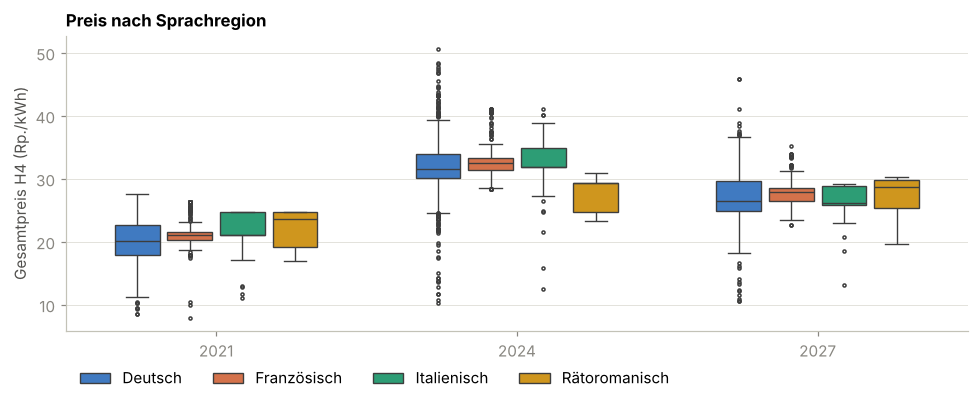

In [20]:
lang_r = df.melt(id_vars="sprachregion", value_vars=[f"total_{j}" for j in JAHRE],
                 var_name="jahr", value_name="preis")
lang_r["jahr"] = lang_r["jahr"].str[-4:]

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=lang_r, x="jahr", y="preis", hue="sprachregion", hue_order=REGIONEN,
            palette=REGION_FARBE, width=0.7, fliersize=2, linewidth=0.9, gap=0.15, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("Gesamtpreis H4 (Rp./kWh)")
ax.set_title("Preis nach Sprachregion", loc="left")
ax.legend(title="", frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.08))
fig.tight_layout()

Die rätoromanische Gruppe umfasst nur 16 Gemeinden. Ihre Mittelwerte schwanken entsprechend stark und sollten nicht überinterpretiert werden.

### 6.2 Kantone

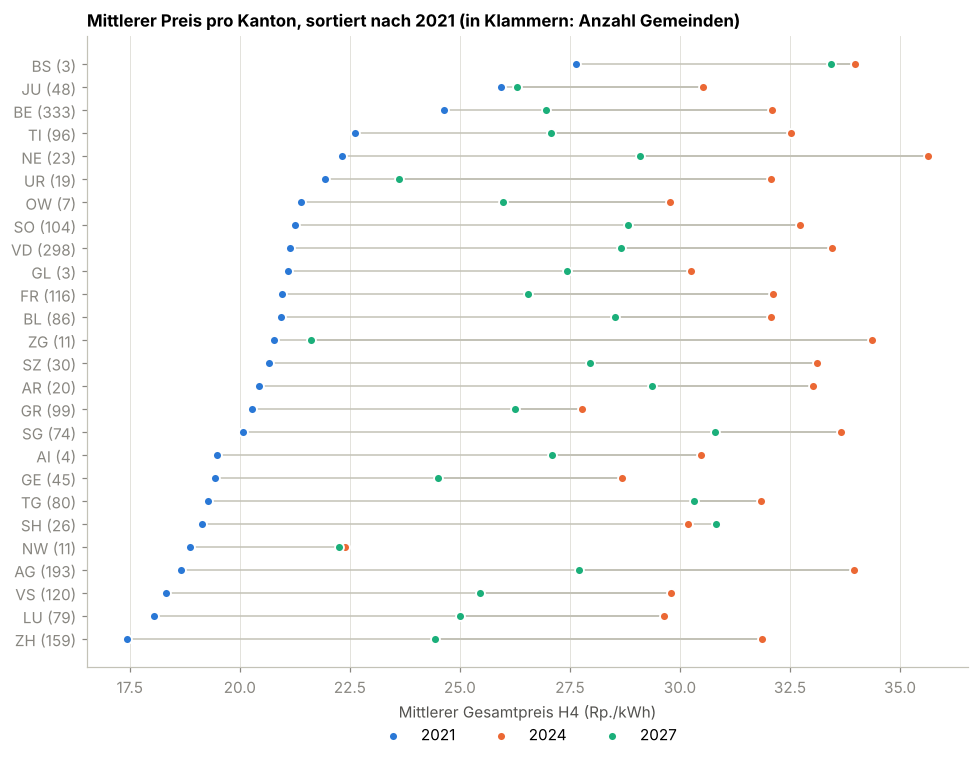

In [21]:
kanton_mittel = df.groupby("kanton")[[f"total_{j}" for j in JAHRE]].mean()
kanton_mittel["n"] = df["kanton"].value_counts()
kanton_mittel = kanton_mittel.sort_values("total_2021")

fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(kanton_mittel))
for j in JAHRE:
    ax.scatter(kanton_mittel[f"total_{j}"], y, color=FARBE[j], s=34, label=str(j), zorder=3,
               edgecolors="white", linewidths=1.2)
for i, (_, zeile) in enumerate(kanton_mittel.iterrows()):
    ax.plot([zeile[f"total_{j}"] for j in JAHRE], [i] * 3, color="#c3c2b7", linewidth=1, zorder=2)
ax.set_yticks(y, [f"{k} ({int(n)})" for k, n in zip(kanton_mittel.index, kanton_mittel["n"])])
ax.set_xlabel("Mittlerer Gesamtpreis H4 (Rp./kWh)")
ax.set_title("Mittlerer Preis pro Kanton, sortiert nach 2021 (in Klammern: Anzahl Gemeinden)", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.07))
ax.grid(axis="y", visible=False)
fig.tight_layout()

#### Interpretation

Zwischen den Sprachregionen sind die Unterschiede klein. 2021 war die Deutschschweiz im Mittel rund 1 Rp. günstiger als die Romandie und 1.5 Rp. günstiger als das Tessin. 2027 liegen die drei grossen Regionen fast gleich auf (27.2, 27.5 und 26.8 Rp.). Auffällig ist die Streuung: Die Romandie hat eine sehr schmale Box, die Deutschschweiz eine breite. Das hängt damit zusammen, wie viele Betreiber eine Region hat (Abschnitt 8.1: 425 Betreiber in der Deutschschweiz, 32 in der Romandie).

Zwischen den Kantonen sind die Unterschiede viel grösser, und die Reihenfolge verschiebt sich. Zürich war 2021 mit 17.4 Rp. der günstigste Kanton, 2027 liegt es mit 24.4 Rp. auf Rang 4 von 26 (günstiger sind nur Zug, Nidwalden und Uri). Der Aargau stieg von 18.7 auf 34.0 Rp. (2024), Neuenburg auf 35.6 Rp. Nidwalden und Graubünden blieben auch 2024 vergleichsweise günstig.

Kleine Kantone mit wenigen Gemeinden (Basel-Stadt 3, Glarus 3, Appenzell Innerrhoden 4) sind Mittelwerte über sehr wenige Werte und deshalb wenig aussagekräftig.

## 7 · Netzbetreiber

Die Preise legen nicht die Gemeinden fest, sondern die Netzbetreiber. Alle Gemeinden eines Betreibers haben (bis auf Gemeinden mit mehreren Betreibern) denselben Preis. Dieser Abschnitt misst, wie stark das die Daten prägt.

In [22]:
pro_betreiber = df.groupby("netzbetreiber_id").size()
print(f"Netzbetreiber: {len(pro_betreiber)}")
print(f"Betreiber mit genau einer Gemeinde: {(pro_betreiber == 1).sum()} ({(pro_betreiber == 1).mean():.0%})")
print(f"Grösster Betreiber: {pro_betreiber.max()} Gemeinden "
      f"({df.loc[df['netzbetreiber_id'] == pro_betreiber.idxmax(), 'netzbetreiber'].iloc[0]})")
print(f"Die fünf grössten Betreiber versorgen zusammen {pro_betreiber.nlargest(5).sum()} Gemeinden "
      f"({pro_betreiber.nlargest(5).sum() / len(df):.0%})")

Netzbetreiber: 485
Betreiber mit genau einer Gemeinde: 387 (80%)
Grösster Betreiber: 315 Gemeinden (BKW Energie AG)
Die fünf grössten Betreiber versorgen zusammen 911 Gemeinden (44%)

In [23]:
def varianz_zwischen(werte: pd.Series, gruppe: pd.Series) -> float:
    # Anteil der Varianz, der auf Unterschiede zwischen den Gruppen entfällt (eta²)
    gesamt = ((werte - werte.mean()) ** 2).sum()
    zwischen = werte.groupby(gruppe).transform("mean")
    return ((zwischen - werte.mean()) ** 2).sum() / gesamt

pd.DataFrame({
    j: {"zwischen Netzbetreibern": varianz_zwischen(df[f"total_{j}"], df["netzbetreiber_id"]),
        "zwischen Kantonen": varianz_zwischen(df[f"total_{j}"], df["kanton"]),
        "zwischen Sprachregionen": varianz_zwischen(df[f"total_{j}"], df["sprachregion"])}
    for j in JAHRE
}).map(lambda v: f"{v:.1%}")

,2021,2024,2027
zwischen Netzbetreibern,95.0%,94.0%,96.8%
zwischen Kantonen,60.3%,23.1%,35.2%
zwischen Sprachregionen,3.0%,1.7%,0.4%


#### Interpretation

Die Versorgungsstruktur ist extrem ungleich. 80 Prozent der 485 Betreiber versorgen genau eine Gemeinde, gleichzeitig versorgen die fünf grössten zusammen 44 Prozent aller Gemeinden, die BKW allein 315.

Der Netzbetreiber erklärt 94 bis 97 Prozent der Preisunterschiede zwischen den Gemeinden. Wer weiss, welcher Betreiber eine Gemeinde versorgt, kennt ihren Preis fast vollständig. Der Kanton erklärt 60 Prozent (2021), 23 Prozent (2024) und 35 Prozent (2027), die Sprachregion nur 0.4 bis 3 Prozent.

Zwei Folgen für die weitere Analyse:

1. Gemeindemerkmale können den Preis nur über den Betreiber beeinflussen. Ein Zusammenhang zwischen Dichte und Preis heisst also eigentlich: Dichte Gemeinden werden von anderen Betreibern versorgt als ländliche.
2. Die 2087 Gemeinden sind keine unabhängigen Beobachtungen. Tests auf Gemeindeebene liefern zu kleine p-Werte. Jeder Test wird deshalb in Abschnitt 8 zusätzlich auf Betreiberebene gerechnet.

## 8 · Statistische Tests

Signifikanzniveau 5 Prozent. Weil viele Tests gerechnet werden, wird bei den Korrelationen zusätzlich die Bonferroni-Korrektur angegeben.

**Vorbehalt für alle Tests auf Gemeindeebene:** Die Gemeinden sind keine unabhängigen Beobachtungen, weil die Gemeinden eines Netzbetreibers denselben Preis haben (Abschnitt 7). Die effektive Fallzahl liegt bei rund 500, nicht bei 2087. Die p-Werte fallen dadurch zu klein aus. Deshalb wird jeder Test zusätzlich auf Betreiberebene wiederholt.

### 8.1 Betreiberebene vorbereiten
Pro Netzbetreiber wird der mittlere Preis seiner Gemeinden genommen. Kanton und Sprachregion sind die, in denen die meisten seiner Gemeinden liegen.

In [24]:
def haeufigster(x):
    return x.mode().iloc[0]

betreiber = df.groupby("netzbetreiber_id").agg(
    gemeinden=("gemeinde_nr", "size"),
    **{f"total_{j}": (f"total_{j}", "mean") for j in JAHRE},
    anstieg_21_24=("anstieg_21_24", "mean"),
    anstieg_21_27=("anstieg_21_27", "mean"),
    kanton=("kanton", haeufigster),
    sprachregion=("sprachregion", haeufigster),
    einwohner=("einwohner", "sum"),
    flaeche_total=("flaeche_total", "sum"),
    anteil_65plus=("anteil_65plus", "mean"),
)
betreiber["dichte"] = betreiber["einwohner"] / betreiber["flaeche_total"]
mehrere_kantone = df.groupby("netzbetreiber_id")["kanton"].nunique().gt(1).sum()
print(f"{len(betreiber)} Netzbetreiber, davon {mehrere_kantone} in mehr als einem Kanton tätig")
betreiber["sprachregion"].value_counts()

485 Netzbetreiber, davon 18 in mehr als einem Kanton tätig

sprachregion
Deutsch          425
Französisch       32
Italienisch       21
Rätoromanisch      7
Name: count, dtype: int64

### 8.2 Gepaarter t-Test: Ist der Preis 2027 höher als 2021?

Dieselbe Gemeinde wird in zwei Jahren gemessen, deshalb ein gepaarter Test. Als Gegenprobe ohne Normalverteilungsannahme der Wilcoxon-Vorzeichen-Rang-Test.

Nullhypothese: Der mittlere Preis ist in beiden Jahren gleich.

In [25]:
zeilen = []
for a, b in paare:
    for ebene, daten in [("Gemeinden", df), ("Netzbetreiber", betreiber)]:
        diff = daten[f"total_{b}"] - daten[f"total_{a}"]
        t = stats.ttest_rel(daten[f"total_{b}"], daten[f"total_{a}"])
        w = stats.wilcoxon(daten[f"total_{b}"], daten[f"total_{a}"])
        zeilen.append({"Vergleich": f"{a} → {b}", "Ebene": ebene, "n": len(daten),
                       "mittlere Differenz (Rp.)": round(diff.mean(), 2),
                       "t": round(t.statistic, 1), "p (t-Test)": t.pvalue, "p (Wilcoxon)": w.pvalue})
pd.DataFrame(zeilen)

,Vergleich,Ebene,n,mittlere Differenz (Rp.),t,p (t-Test),p (Wilcoxon)
0,2021 → 2024,Gemeinden,2087,11.13,115.7,0.000000e+00,0.000000e+00
1,2021 → 2024,Netzbetreiber,485,12.95,56.4,9.256121e-215,3.560164e-81
2,2024 → 2027,Gemeinden,2087,-4.74,-69.7,0.000000e+00,0.000000e+00
3,2024 → 2027,Netzbetreiber,485,-4.09,-19.3,5.664188e-62,4.851966e-51
4,2021 → 2027,Gemeinden,2087,6.39,75.7,0.000000e+00,0.000000e+00
5,2021 → 2027,Netzbetreiber,485,8.86,49.0,1.151380e-189,3.582291e-81


#### Interpretation

Alle drei Veränderungen sind auf beiden Ebenen hochsignifikant, der Wilcoxon-Test bestätigt das ohne Normalverteilungsannahme. Bei Differenzen von 4 bis 13 Rappen und dieser Fallzahl ist das keine Überraschung.

Aufschlussreicher ist der Unterschied zwischen den Ebenen: Pro Betreiber gerechnet stieg der Preis von 2021 auf 2027 um 8.9 Rp., pro Gemeinde nur um 6.4 Rp. Weil auf Betreiberebene jeder Betreiber gleich zählt, heisst das: Die vielen kleinen Betreiber sind stärker gestiegen als die wenigen grossen, die viele Gemeinden versorgen.

Der t-Test zählt nicht für Bonus 4, dort sind nur Chi-Quadrat, ANOVA und Korrelation genannt. Er beantwortet aber die Grundfrage, ob es den Preisanstieg überhaupt gibt.

### 8.3 ANOVA: Unterscheiden sich die Preise zwischen den Sprachregionen?

Nullhypothese: Der mittlere Preis ist in allen Sprachregionen gleich.

Die klassische ANOVA setzt gleiche Varianzen in den Gruppen voraus. Das wird mit dem Levene-Test geprüft. Ist die Annahme verletzt, zählt der Alexander-Govern-Test, eine ANOVA ohne Annahme gleicher Varianzen. Der Kruskal-Wallis-Test vergleicht Ränge statt Mittelwerte und dient als Gegenprobe ohne Normalverteilungsannahme. Als Effektstärke wird eta² angegeben: der Anteil der Preisstreuung, den die Gruppenzugehörigkeit erklärt.

In [26]:
def anova_tabelle(daten: pd.DataFrame, gruppe: str, ziele: list, ebene: str) -> pd.DataFrame:
    zeilen = []
    for ziel in ziele:
        gruppen = [g[ziel].values for _, g in daten.groupby(gruppe) if len(g) >= 2]
        # Alexander-Govern gewichtet mit 1/Varianz und braucht Gruppen mit Streuung.
        # Kantone, in denen alle Gemeinden denselben Preis haben, fallen dort weg.
        mit_streuung = [g for g in gruppen if np.ptp(g) > 0]
        f = stats.f_oneway(*gruppen)
        zeilen.append({
            "Ebene": ebene, "Grösse": ZIELE.get(ziel, ziel), "Gruppen": len(gruppen), "n": sum(map(len, gruppen)),
            "F": round(f.statistic, 1), "p (ANOVA)": f.pvalue,
            "p (Levene)": stats.levene(*gruppen).pvalue,
            "p (Alexander-Govern)": stats.alexandergovern(*mit_streuung).pvalue,
            "Gruppen ohne Streuung": len(gruppen) - len(mit_streuung),
            "p (Kruskal-Wallis)": stats.kruskal(*gruppen).pvalue,
            "eta²": round(varianz_zwischen(daten[ziel], daten[gruppe]), 3),
        })
    return pd.DataFrame(zeilen)

ZIEL_SPALTEN = ["total_2021", "total_2024", "total_2027", "anstieg_21_24", "anstieg_21_27"]
anova_region = pd.concat([
    anova_tabelle(df, "sprachregion", ZIEL_SPALTEN, "Gemeinden"),
    anova_tabelle(betreiber, "sprachregion", ZIEL_SPALTEN, "Netzbetreiber"),
], ignore_index=True)
anova_region

,Ebene,Grösse,Gruppen,n,F,p (ANOVA),p (Levene),p (Alexander-Govern),Gruppen ohne Streuung,p (Kruskal-Wallis),eta²
0,Gemeinden,Preis 2021,4,2087,21.4,1.184506e-13,7.634853e-29,1.362372e-15,0,3.778367e-24,0.030
1,Gemeinden,Preis 2024,4,2087,11.8,1.232976e-07,1.178384e-19,1.947145e-08,0,1.125931e-13,0.017
2,Gemeinden,Preis 2027,4,2087,2.9,3.284969e-02,6.441775e-38,8.909422e-04,0,5.035400e-05,0.004
3,Gemeinden,Anstieg 21–24,4,2087,10.0,1.543401e-06,2.425241e-42,2.423445e-10,0,2.141412e-11,0.014
4,Gemeinden,Anstieg 21–27,4,2087,11.2,2.604794e-07,1.365603e-38,1.486072e-18,0,2.328651e-17,0.016
5,Netzbetreiber,Preis 2021,4,485,7.9,3.691010e-05,4.386356e-01,2.303611e-03,0,3.464869e-06,0.047
6,Netzbetreiber,Preis 2024,4,485,5.8,6.830808e-04,1.148928e-01,1.986768e-04,0,5.736086e-04,0.035
7,Netzbetreiber,Preis 2027,4,485,5.8,7.094119e-04,1.685701e-01,3.624483e-04,0,3.811793e-04,0.035
8,Netzbetreiber,Anstieg 21–24,4,485,7.4,7.702149e-05,1.046466e-01,1.441284e-05,0,1.039265e-04,0.044
9,Netzbetreiber,Anstieg 21–27,4,485,9.4,4.757722e-06,3.578022e-02,2.868223e-07,0,5.861611e-07,0.055


Die ANOVA sagt nur, dass sich mindestens zwei Gruppen unterscheiden. Welche, zeigt der Post-hoc-Test nach Tukey (paarweise Vergleiche mit korrigierten p-Werten). Gezeigt für 2021, das Jahr mit dem deutlichsten Unterschied.

In [27]:
gruppen_2021 = [df.loc[df["sprachregion"] == r, "total_2021"].values for r in REGIONEN]
tukey = stats.tukey_hsd(*gruppen_2021)
tukey_tabelle = pd.DataFrame(
    [{"Gruppe A": REGIONEN[i], "Gruppe B": REGIONEN[k],
      "Differenz A − B (Rp.)": round(gruppen_2021[i].mean() - gruppen_2021[k].mean(), 2),
      "p (Tukey)": round(tukey.pvalue[i, k], 4)}
     for i in range(4) for k in range(i + 1, 4)]
)
tukey_tabelle

,Gruppe A,Gruppe B,Differenz A − B (Rp.),p (Tukey)
0,Deutsch,Französisch,-0.96,0.0000
1,Deutsch,Italienisch,-1.52,0.0000
2,Deutsch,Rätoromanisch,-1.45,0.2053
3,Französisch,Italienisch,-0.56,0.2570
4,Französisch,Rätoromanisch,-0.49,0.9129
5,Italienisch,Rätoromanisch,0.07,0.9998


### 8.4 ANOVA: Unterscheiden sich die Preise zwischen den Kantonen?

In [28]:
anova_kanton = pd.concat([
    anova_tabelle(df, "kanton", ZIEL_SPALTEN, "Gemeinden"),
    anova_tabelle(betreiber, "kanton", ZIEL_SPALTEN, "Netzbetreiber"),
], ignore_index=True)
anova_kanton

,Ebene,Grösse,Gruppen,n,F,p (ANOVA),p (Levene),p (Alexander-Govern),Gruppen ohne Streuung,p (Kruskal-Wallis),eta²
0,Gemeinden,Preis 2021,26,2087,125.3,0.000000e+00,3.498305e-83,0.000000e+00,2,2.121713e-266,0.603
1,Gemeinden,Preis 2024,26,2087,24.8,4.377534e-99,1.961052e-79,8.089292e-261,2,2.489474e-127,0.231
2,Gemeinden,Preis 2027,26,2087,44.9,8.187317e-174,2.426995e-81,0.000000e+00,2,9.125054e-181,0.352
3,Gemeinden,Anstieg 21–24,26,2087,51.0,1.607812e-194,3.941107e-86,1.973079e-266,2,8.415157e-172,0.382
4,Gemeinden,Anstieg 21–27,26,2087,76.0,2.727213e-270,4.660297e-76,0.000000e+00,2,4.157398e-195,0.480
5,Netzbetreiber,Preis 2021,22,481,10.8,1.083221e-28,2.437072e-08,1.772005e-31,0,1.052206e-26,0.343
6,Netzbetreiber,Preis 2024,22,481,7.7,9.173746e-20,4.215374e-04,1.246155e-13,0,8.056244e-16,0.261
7,Netzbetreiber,Preis 2027,22,481,10.7,1.174591e-28,2.009798e-03,3.922278e-30,0,4.196303e-27,0.333
8,Netzbetreiber,Anstieg 21–24,22,481,6.1,4.645004e-15,4.093088e-06,1.814931e-12,0,1.638722e-12,0.224
9,Netzbetreiber,Anstieg 21–27,22,481,6.3,1.500779e-15,5.751382e-03,8.407687e-22,0,1.762228e-16,0.228


#### Interpretation Sprachregion

Die ANOVA ist in allen Jahren signifikant, auf Gemeinde- und auf Betreiberebene. Der Levene-Test zeigt auf Gemeindeebene ungleiche Varianzen, deshalb ist der Alexander-Govern-Test massgebend, und er bestätigt das Ergebnis. Der Effekt ist aber klein: Die Sprachregion erklärt 2021 3.0 Prozent der Preisunterschiede, 2027 nur noch 0.4 Prozent. Signifikant heisst hier nicht bedeutsam.

Der Tukey-Test zeigt, wo die Unterschiede liegen: Die Deutschschweiz war 2021 signifikant günstiger als die Romandie (−0.96 Rp.) und das Tessin (−1.52 Rp.). Die rätoromanischen Gemeinden unterscheiden sich von keiner Region signifikant, was bei 16 Gemeinden auch kaum möglich ist.

#### Interpretation Kanton

Der Kanton ist auf beiden Ebenen hochsignifikant, und der Effekt ist gross. Auf Gemeindeebene erklärt er 60 Prozent (2021), 23 Prozent (2024) und 35 Prozent (2027) der Unterschiede. Auf Betreiberebene ist der Rückgang 2024 schwächer: 34, 26 und 33 Prozent. Ein Teil des starken Kantonseffekts 2021 auf Gemeindeebene kommt also daher, dass einzelne grosse kantonale Betreiber viele Gemeinden zum selben tiefen Preis versorgten.

In Basel-Stadt und Obwalden haben alle Gemeinden denselben Preis. Diese zwei Kantone fallen beim Alexander-Govern-Test weg, weil er Gruppen mit Streuung braucht; das Ergebnis ändert sich dadurch nicht. Auf Betreiberebene sind es 22 statt 26 Kantone, weil Kantone mit nur einem Betreiber für eine ANOVA keine Streuung innerhalb der Gruppe haben.

Für die Forschungsfrage heisst das: Die Unterschiede zwischen den Kantonen sind auch 2027 gross, die zwischen den Sprachregionen sind praktisch verschwunden.

### 8.5 Korrelation mit p-Wert: Welche Merkmale hängen mit dem Preis zusammen?

Pearson auf den logarithmierten Merkmalen (lineare Beziehung) und Spearman auf den Rohwerten (monotone Beziehung). Nullhypothese: Die Korrelation ist null.

Gerechnet werden 5 Merkmale mal 5 Zielgrössen, also 25 Tests pro Verfahren. Die Bonferroni-Schwelle liegt damit bei 0.05 / 25 = 0.002.

In [29]:
BONFERRONI = 0.05 / (len(MERKMALE) * len(ZIELE))

def korrelationen(daten: pd.DataFrame, ebene: str) -> pd.DataFrame:
    zeilen = []
    for m in MERKMALE:
        if m not in daten:
            continue
        for ziel, name in ZIELE.items():
            paar = daten[[m, ziel]].dropna()
            x_lin = paar[m] if m == "anteil_65plus" else np.log10(paar[m])
            p = stats.pearsonr(x_lin, paar[ziel])
            s = stats.spearmanr(paar[m], paar[ziel])
            zeilen.append({"Ebene": ebene, "Merkmal": MERKMAL_NAME[m], "Grösse": name, "n": len(paar),
                           "Pearson r": round(p.statistic, 3), "p (Pearson)": p.pvalue,
                           "Spearman rho": round(s.statistic, 3), "p (Spearman)": s.pvalue,
                           "signifikant nach Bonferroni": p.pvalue < BONFERRONI and s.pvalue < BONFERRONI})
    return pd.DataFrame(zeilen)

korr_gemeinden = korrelationen(df, "Gemeinden")
pd.options.display.float_format = lambda v: f"{v:.3g}"
korr_gemeinden

,Ebene,Merkmal,Grösse,n,Pearson r,p (Pearson),Spearman rho,p (Spearman),signifikant nach Bonferroni
0,Gemeinden,Einwohner,Preis 2021,2087,-0.145,3.05e-11,-0.169,8.03e-15,True
1,Gemeinden,Einwohner,Preis 2024,2087,0.115,1.45e-07,0.085,9.75e-05,True
2,Gemeinden,Einwohner,Preis 2027,2087,0.031,0.159,-0.023,0.297,False
3,Gemeinden,Einwohner,Anstieg 21–24,2087,0.196,1.89e-19,0.195,2.56e-19,True
4,Gemeinden,Einwohner,Anstieg 21–27,2087,0.137,3.7e-10,0.112,2.91e-07,True
5,Gemeinden,Dichte (Einw./km²),Preis 2021,2087,-0.134,8.75e-10,-0.206,1.62e-21,True
6,Gemeinden,Dichte (Einw./km²),Preis 2024,2087,0.205,3.72e-21,0.142,6.49e-11,True
7,Gemeinden,Dichte (Einw./km²),Preis 2027,2087,0.07,0.00141,-0.013,0.556,False
8,Gemeinden,Dichte (Einw./km²),Anstieg 21–24,2087,0.264,1.29e-34,0.271,2.39e-36,True
9,Gemeinden,Dichte (Einw./km²),Anstieg 21–27,2087,0.159,2.91e-13,0.164,4.18e-14,True


In [30]:
# Gegenprobe auf Betreiberebene (Beschäftigte fehlen dort, weil bei 88 Gemeinden unterdrückt)
korr_betreiber = korrelationen(betreiber, "Netzbetreiber")
vergleich = korr_gemeinden.merge(korr_betreiber, on=["Merkmal", "Grösse"], suffixes=(" Gem.", " Betr."))
vergleich[["Merkmal", "Grösse", "Spearman rho Gem.", "p (Spearman) Gem.",
           "Spearman rho Betr.", "p (Spearman) Betr.", "signifikant nach Bonferroni Betr."]]

,Merkmal,Grösse,Spearman rho Gem.,p (Spearman) Gem.,Spearman rho Betr.,p (Spearman) Betr.,signifikant nach Bonferroni Betr.
0,Einwohner,Preis 2021,-0.169,8.03e-15,0.234,1.83e-07,True
1,Einwohner,Preis 2024,0.085,9.75e-05,0.167,0.000227,True
2,Einwohner,Preis 2027,-0.023,0.297,-0.056,0.221,False
3,Einwohner,Anstieg 21–24,0.195,2.56e-19,0.068,0.136,False
4,Einwohner,Anstieg 21–27,0.112,2.91e-07,-0.195,1.47e-05,True
5,Dichte (Einw./km²),Preis 2021,-0.206,1.62e-21,0.047,0.3,False
6,Dichte (Einw./km²),Preis 2024,0.142,6.49e-11,0.272,1.11e-09,True
7,Dichte (Einw./km²),Preis 2027,-0.013,0.556,0.024,0.602,False
8,Dichte (Einw./km²),Anstieg 21–24,0.271,2.39e-36,0.268,1.9e-09,True
9,Dichte (Einw./km²),Anstieg 21–27,0.164,4.18e-14,0.019,0.676,False


#### Interpretation

Auf Gemeindeebene sind 2021 und 2024 die meisten Zusammenhänge auch nach Bonferroni signifikant, 2027 kein einziger. Das bestätigt den Befund aus Abschnitt 5: Die Zusammenhänge bestanden vor der Krise und auf ihrem Höhepunkt, mit umgekehrtem Vorzeichen, und sind 2027 verschwunden.

Die Gegenprobe auf Betreiberebene trennt robuste von unsicheren Befunden.

Robust, auf beiden Ebenen signifikant nach Bonferroni und mit gleichem Vorzeichen:

- Anteil 65+ und Anstieg (21–24 und 21–27): negativ. Ältere Gemeinden hatten einen schwächeren Anstieg.
- Dichte und Preis 2024 sowie Dichte und Anstieg 21–24: positiv. Dichte Gemeinden waren auf dem Höhepunkt teurer.
- Fläche und Anstieg 21–24: negativ. Grossflächige Gemeinden stiegen weniger.

Nicht robust:

- Dichte und Preis 2021 (Gemeinden −0.21, Betreiber 0.05 und nicht signifikant). Der tiefe Preis dichter Gemeinden 2021 geht auf wenige grosse städtische Betreiber zurück und gilt nicht für Betreiber allgemein.
- Einwohner und Anstieg 21–27 kehren das Vorzeichen um (+0.11 und −0.20). Auf Betreiberebene ist «Einwohner» die Summe der versorgten Bevölkerung, also die Grösse des Betreibers. Grosse Betreiber stiegen weniger, grosse Gemeinden mehr. Das sind zwei verschiedene Aussagen.

Kein Zusammenhang mit einem Gemeindemerkmal erreicht einen Betrag von 0.28. Die Merkmale tragen zur Erklärung bei, aber wenig.

### 8.6 Korrelation mit der Grösse des Netzbetreibers

Unterfrage 2 nennt neben den Gemeindemerkmalen ausdrücklich die Grösse des Netzbetreibers. Gemessen wird sie als Zahl der Gemeinden, die der Betreiber 2027 in der Kategorie H4 beliefert (`anz_gemeinden_betreiber`, Integrationsdokumentation Abschnitt 7b). Sie ist keine Eigenschaft der Gemeinde, sondern ihres Betreibers, und wird deshalb getrennt ausgewiesen.

Auf Gemeindeebene erhält jede Gemeinde die Grösse ihres Betreibers. Auf Betreiberebene zählt jeder Betreiber einmal. Pearson auf dem Logarithmus der Grösse, Spearman auf den Rohwerten. Fünf Tests pro Verfahren, die Bonferroni-Schwelle liegt bei 0.05 / 5 = 0.01.

In [31]:
BONF_GROESSE = 0.05 / len(ZIELE)
betreiber["groesse"] = df.groupby("netzbetreiber_id")["anz_gemeinden_betreiber"].first()

zeilen = []
for ebene, daten, spalte in [("Gemeinden", df, "anz_gemeinden_betreiber"), ("Netzbetreiber", betreiber, "groesse")]:
    for ziel, name in ZIELE.items():
        p = stats.pearsonr(np.log10(daten[spalte]), daten[ziel])
        s = stats.spearmanr(daten[spalte], daten[ziel])
        zeilen.append({"Ebene": ebene, "Grösse": name, "n": len(daten),
                       "Pearson r (log)": round(p.statistic, 3), "p (Pearson)": p.pvalue,
                       "Spearman rho": round(s.statistic, 3), "p (Spearman)": s.pvalue,
                       "signifikant nach Bonferroni": p.pvalue < BONF_GROESSE and s.pvalue < BONF_GROESSE})
print(f"Betreiber mit genau einer Gemeinde: {(betreiber['groesse'] == 1).mean():.0%}")
pd.DataFrame(zeilen)

Betreiber mit genau einer Gemeinde: 77%

,Ebene,Grösse,n,Pearson r (log),p (Pearson),Spearman rho,p (Spearman),signifikant nach Bonferroni
0,Gemeinden,Preis 2021,2087,0.391,3.02e-77,0.442,8.94e-101,True
1,Gemeinden,Preis 2024,2087,-0.067,0.00228,-0.119,4.57e-08,True
2,Gemeinden,Preis 2027,2087,-0.195,2.03e-19,-0.205,2.46e-21,True
3,Gemeinden,Anstieg 21–24,2087,-0.323,8.18e-52,-0.329,5.89e-54,True
4,Gemeinden,Anstieg 21–27,2087,-0.458,1.4e-108,-0.444,1.06e-101,True
5,Netzbetreiber,Preis 2021,485,0.16,0.000421,0.18,6.69e-05,True
6,Netzbetreiber,Preis 2024,485,0.008,0.866,0.042,0.36,False
7,Netzbetreiber,Preis 2027,485,-0.09,0.0472,-0.108,0.017,False
8,Netzbetreiber,Anstieg 21–24,485,-0.079,0.0814,-0.026,0.575,False
9,Netzbetreiber,Anstieg 21–27,485,-0.211,2.78e-06,-0.213,2.22e-06,True


#### Interpretation

Auf Gemeindeebene ist die Grösse des Netzbetreibers der stärkste Zusammenhang im ganzen Notebook. Gemeinden grosser Betreiber waren 2021 teurer (rho = 0.44) und hatten danach den kleineren Anstieg (rho = −0.33 bis 2024 und −0.44 bis 2027). 2027 sind sie leicht günstiger (−0.21). Mit dem Preis 2024 besteht nur ein schwacher Zusammenhang (rho = −0.12).

Auf Betreiberebene ist der Zusammenhang viel schwächer. Signifikant nach Bonferroni bleiben nur der Preis 2021 (rho = 0.18) und der Anstieg 2021 bis 2027 (rho = −0.21). 77 Prozent der Betreiber versorgen genau eine Gemeinde, das Merkmal hat auf dieser Ebene also wenig Streuung.

Der Unterschied zwischen den Ebenen hat denselben Grund wie in Abschnitt 8.2: Auf Gemeindeebene prägen die wenigen grossen Betreiber das Ergebnis, weil sie viele Gemeinden versorgen. Notebook 04 prüft, ob der Zusammenhang hält, wenn die Gemeindemerkmale gleichzeitig berücksichtigt werden. Auf Gemeindeebene tut er das, auf Betreiberebene nicht (Notebook 04, Abschnitt 5).

## 9 · Zwischenfazit

### Unterfrage 1, Unterschiede zwischen Gemeinden, Kantonen und Sprachregionen

Der Kanton erklärt einen grossen Teil der Preisunterschiede (23 bis 60 Prozent), die Sprachregion fast nichts mehr (0.4 Prozent 2027). Welcher Bestandteil die Unterschiede ausmacht, hat sich mit der Krise umgedreht: 2021 die Netznutzung, 2024 die Energie, 2027 wieder beide etwa gleich.

### Unterfrage 2, Gemeindemerkmale

Die Zusammenhänge sind schwach (höchstens 0.28) und gelten auf Betreiberebene nur teilweise. Robust sind der Anteil 65+ und die Dichte beim Anstieg 2021 bis 2024. Stärker hängt die Grösse des Netzbetreibers mit dem Preis zusammen (bis 0.44 auf Gemeindeebene), aber auch sie vor allem wegen der wenigen grossen Betreiber (Abschnitt 8.6).

### Hauptfrage, haben sich die Zusammenhänge verändert

Ja. Die Rangfolge der Gemeinden wurde durch die Krise fast vollständig neu gemischt (rho = 0.08 zwischen 2021 und 2024), mehrere Zusammenhänge kehren ihr Vorzeichen um, und 2027 ist kein Zusammenhang mehr signifikant.

### Vorbehalte

Der Netzbetreiber erklärt 94 bis 97 Prozent der Unterschiede. Der Preis einer Gemeinde hängt weit stärker davon ab, wer sie versorgt, als von ihren eigenen Merkmalen.

Die Gemeindemerkmale stammen aus den Jahren 2016 bis 2019, die Preise aus 2021 bis 2027 (Abschnitt 5).

### Festlegungen für den zweiten Teil (Regression und k-means)

- Einwohner, Dichte, Fläche und Beschäftigte gehen logarithmiert ins Modell.
- Einwohner und Beschäftigte nicht gemeinsam verwenden (r = 0.94), Einwohner und Dichte nur mit Vorsicht (r = 0.68).
- Zielgrössen: Preis 2021, 2024 und 2027 mit demselben Modell, zusätzlich der Anstieg 2021 bis 2024.
- Modell mit und ohne Kanton rechnen, um zu sehen, wie viel die Gemeindemerkmale über den Kanton hinaus erklären.
- Standardfehler nach Netzbetreiber clustern und das Modell zusätzlich auf Betreiberebene rechnen.
- Zwei Varianten wegen der fehlenden Beschäftigtenzahlen: 2087 Gemeinden ohne, 1999 Gemeinden mit diesem Merkmal.

In [32]:
con.close()
pd.reset_option("display.float_format")